# EDA: Mackey-Glass & CHB-MIT Datasets
Khám phá dữ liệu cho thực nghiệm Future-Guided Learning (FGL). Chạy local trong repo, không cần GPU.

Tham số và quy trình đối chiếu với bài báo gốc: Gunasekaran et al., *A Predictive Approach To Enhance Time-Series Forecasting* (arXiv:2410.15217).

In [1]:
import os
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True

In [2]:
# Đường dẫn local (file này nằm ở repro/notebook/, dữ liệu nằm ở repro/build/)
MG_PATH = "../build/mackey_glass/data.pkl"
CHBMIT_DIR = "../build/CHBMIT/Dataset"

# 12 bệnh nhân thực nghiệm trong bài báo gốc (Table 1) - KHÔNG phải toàn bộ 23 bệnh nhân CHB-MIT
PATIENT_LIST = ['1', '2', '3', '5', '9', '10', '13', '18', '19', '20', '21', '23']

assert os.path.exists(MG_PATH), f"Không tìm thấy {MG_PATH}"
assert os.path.exists(CHBMIT_DIR), f"Không tìm thấy {CHBMIT_DIR}"
print("OK - đường dẫn hợp lệ.")

OK - đường dẫn hợp lệ.


---
## 1. Mackey-Glass Time Series

In [3]:
with open(MG_PATH, 'rb') as f:
    mg_raw = pickle.load(f)

# data.pkl lưu tensor (N, 2) với 2 cột giống hệt nhau (xem utils/generate.py) -> chỉ lấy 1 cột
mg = np.asarray(mg_raw)
if mg.ndim == 2:
    mg = mg[:, 0]
mg = mg.astype(np.float64)

print(f"Độ dài chuỗi: {len(mg)} điểm")
print(f"(Theo bài báo gốc: tổng 10.000 điểm, chia 6.000 train / 2.000 val / 2.000 test)")

Độ dài chuỗi: 10000 điểm
(Theo bài báo gốc: tổng 10.000 điểm, chia 6.000 train / 2.000 val / 2.000 test)


In [4]:
print("Thống kê mô tả:")
print(f"  Min:              {mg.min():.4f}")
print(f"  Max:              {mg.max():.4f}")
print(f"  Mean:             {mg.mean():.4f}")
print(f"  Std:              {mg.std():.4f}")

def autocorr(x, lag):
    return np.corrcoef(x[:-lag], x[lag:])[0, 1]

print("\nTự tương quan (autocorrelation):")
for lag in [1, 5, 10, 50]:
    print(f"  lag={lag:<3d}  Corr = {autocorr(mg, lag):.4f}")

Thống kê mô tả:
  Min:              0.4175
  Max:              1.3199
  Mean:             0.9301
  Std:              0.2262

Tự tương quan (autocorrelation):
  lag=1    Corr = 0.9894
  lag=5    Corr = 0.7575
  lag=10   Corr = 0.2309
  lag=50   Corr = 0.7011


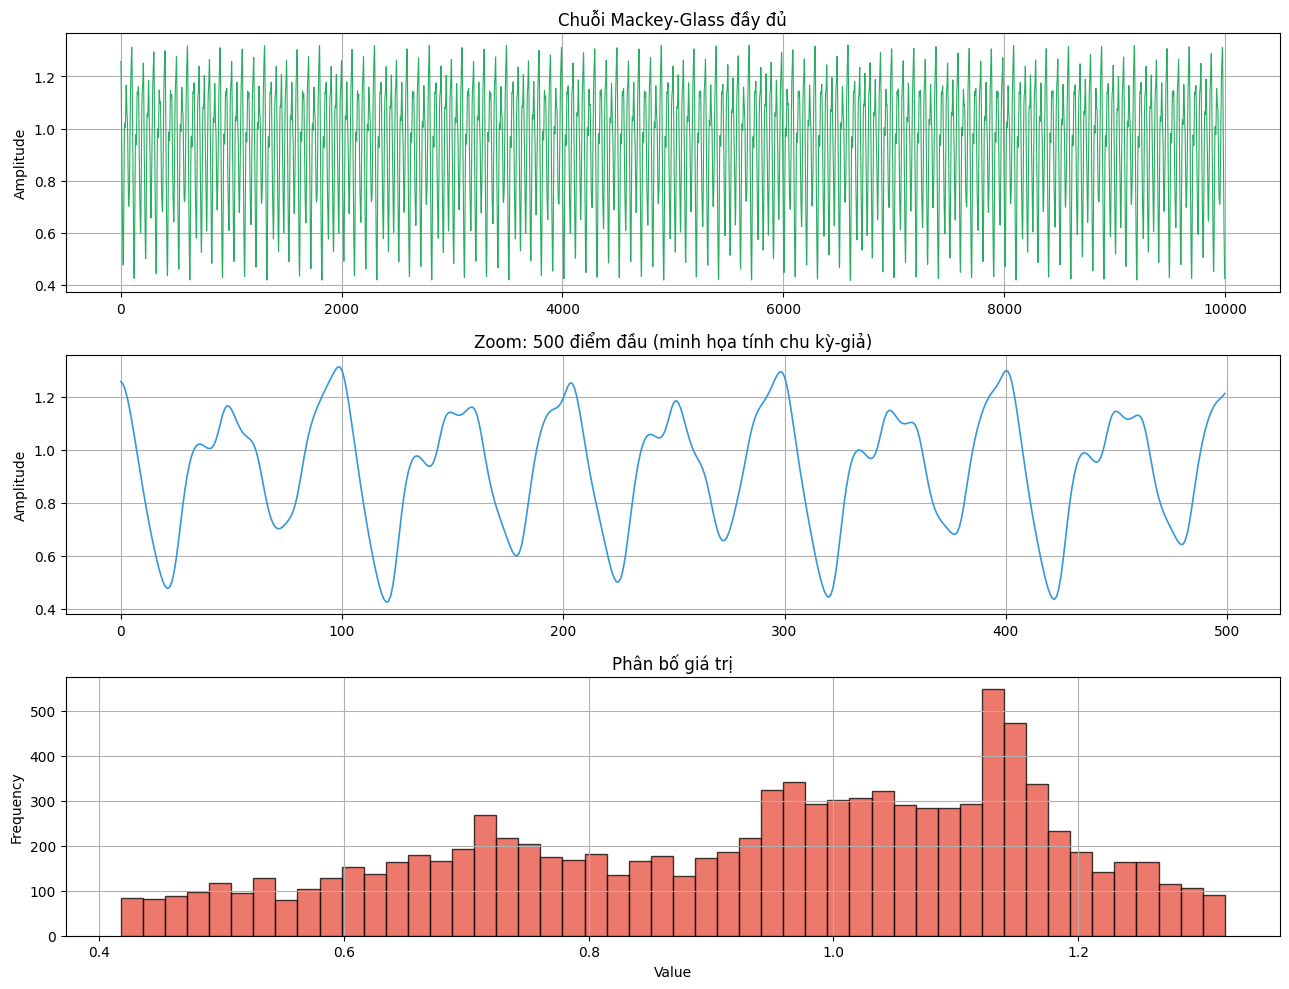

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10))

axes[0].plot(mg, color='#27ae60', linewidth=0.8)
axes[0].set_title('Chuỗi Mackey-Glass đầy đủ')
axes[0].set_ylabel('Amplitude')

axes[1].plot(mg[:500], color='#3498db', linewidth=1.2)
axes[1].set_title('Zoom: 500 điểm đầu (minh họa tính chu kỳ-giả)')
axes[1].set_ylabel('Amplitude')

axes[2].hist(mg, bins=50, color='#e74c3c', alpha=0.75, edgecolor='black')
axes[2].set_title('Phân bố giá trị')
axes[2].set_xlabel('Value')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

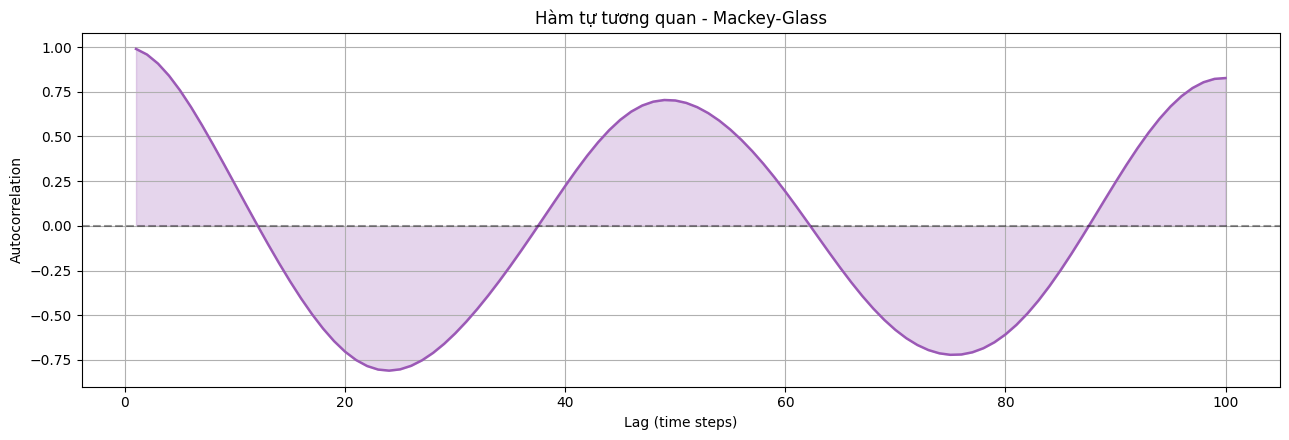

Quan sát: ACF không giảm đơn điệu mà dao động (tăng trở lại ở lag ~50),
phản ánh cấu trúc chu kỳ-giả (quasi-periodic) đặc trưng của hệ hỗn loạn Mackey-Glass,
khác với nhiễu ngẫu nhiên thuần túy (ACF của nhiễu trắng sẽ giảm về 0 và dao động quanh 0).


In [6]:
lags = range(1, 101)
acf_values = [autocorr(mg, lag) for lag in lags]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(lags, acf_values, color='#9b59b6', linewidth=1.8)
ax.axhline(y=0, color='black', linestyle='--', alpha=0.4)
ax.fill_between(lags, acf_values, 0, alpha=0.25, color='#9b59b6')
ax.set_xlabel('Lag (time steps)')
ax.set_ylabel('Autocorrelation')
ax.set_title('Hàm tự tương quan - Mackey-Glass')
plt.tight_layout()
plt.show()

print("Quan sát: ACF không giảm đơn điệu mà dao động (tăng trở lại ở lag ~50),")
print("phản ánh cấu trúc chu kỳ-giả (quasi-periodic) đặc trưng của hệ hỗn loạn Mackey-Glass,")
print("khác với nhiễu ngẫu nhiên thuần túy (ACF của nhiễu trắng sẽ giảm về 0 và dao động quanh 0).")

### 1b. Số chiều đầu vào (lookback window)

Mackey-Glass là chuỗi đơn biến (1 đặc trưng vô hướng/bước thời gian). Số chiều đầu vào của mô
hình chỉ phụ thuộc `lookback_window` — tái hiện đúng logic cắt cửa sổ của
`utils/utils.py::create_time_series_dataset` (không cần import, công thức chỉ là slicing).

In [7]:
def make_windows(x, lookback_window, horizon):
    """Giống hệt create_time_series_dataset trong utils/utils.py (phần cắt cửa sổ)."""
    X_windows, y_windows = [], []
    for i in range(len(x) - lookback_window - horizon + 1):
        X_windows.append(x[i:i + lookback_window])
        y_windows.append(x[i + lookback_window + horizon - 1])
    return np.stack(X_windows), np.stack(y_windows)

LOOKBACK = 8  # tham số mẫu bài báo gốc dùng

for horizon, label in [(1, "teacher"), (5, "student (cấu hình mẫu)")]:
    Xw, yw = make_windows(mg, LOOKBACK, horizon)
    print(f"horizon={horizon:<2d} ({label:<24s}) -> X shape: {Xw.shape}  y shape: {yw.shape}  "
          f"N={Xw.shape[0]}")

print(f"\nMỗi mẫu X là vector {LOOKBACK} chiều (lookback_window={LOOKBACK}); "
      f"y là 1 giá trị vô hướng, sau đó được rời rạc hoá thành num_bins lớp (25 hoặc 50).")


horizon=1  (teacher                 ) -> X shape: (9992, 8)  y shape: (9992,)  N=9992

horizon=5  (student (cấu hình mẫu)  ) -> X shape: (9988, 8)  y shape: (9988,)  N=9988

Mỗi mẫu X là vector 8 chiều (lookback_window=8); y là 1 giá trị vô hướng, sau đó được rời rạc hoá thành num_bins lớp (25 hoặc 50).


---
## 2. CHB-MIT Scalp EEG Dataset

In [8]:
seizure_df = pd.read_csv(os.path.join(CHBMIT_DIR, 'seizure_summary.csv'), header=0)
segment_df = pd.read_csv(os.path.join(CHBMIT_DIR, 'segmentation.csv'), header=None)

def get_patient(fname):
    m = re.match(r'chb0?(\d+)', fname)
    return m.group(1) if m else None

seizure_df['patient'] = seizure_df['File_name'].apply(get_patient)
segment_df['patient'] = segment_df[0].apply(get_patient)

print(f"Tổng số bệnh nhân có trong CHB-MIT (toàn bộ CSV): "
      f"{len(sorted(segment_df['patient'].dropna().unique(), key=int))}")
print(f"Số bệnh nhân dùng trong bài báo gốc / thực nghiệm này: {len(PATIENT_LIST)}")
print(f"  -> {PATIENT_LIST}")

Tổng số bệnh nhân có trong CHB-MIT (toàn bộ CSV): 24
Số bệnh nhân dùng trong bài báo gốc / thực nghiệm này: 12
  -> ['1', '2', '3', '5', '9', '10', '13', '18', '19', '20', '21', '23']


In [9]:
# Đếm đúng theo logic mà utils/load_signals_teacher.py dùng:
#   - ictal: tên tệp xuất hiện trong seizure_summary.csv
#   - interictal: tên tệp có nhãn 0 trong segmentation.csv
ictal_files = seizure_df[seizure_df['patient'].isin(PATIENT_LIST)]['File_name'].unique()
interictal_files = segment_df[(segment_df[1] == 0) & (segment_df['patient'].isin(PATIENT_LIST))]

n_ictal = len(ictal_files)
n_interictal = len(interictal_files)
n_total = n_ictal + n_interictal

print(f"Ictal:        {n_ictal:4d} tệp  ({n_ictal/n_total*100:.1f}%)")
print(f"Interictal:   {n_interictal:4d} tệp  ({n_interictal/n_total*100:.1f}%)")
print(f"Tổng:         {n_total:4d} tệp")
print(f"Tỷ lệ mất cân bằng (interictal:ictal) ~ 1:{n_interictal/n_ictal:.1f}")

Ictal:          62 tệp  (22.6%)
Interictal:    212 tệp  (77.4%)
Tổng:          274 tệp
Tỷ lệ mất cân bằng (interictal:ictal) ~ 1:3.4


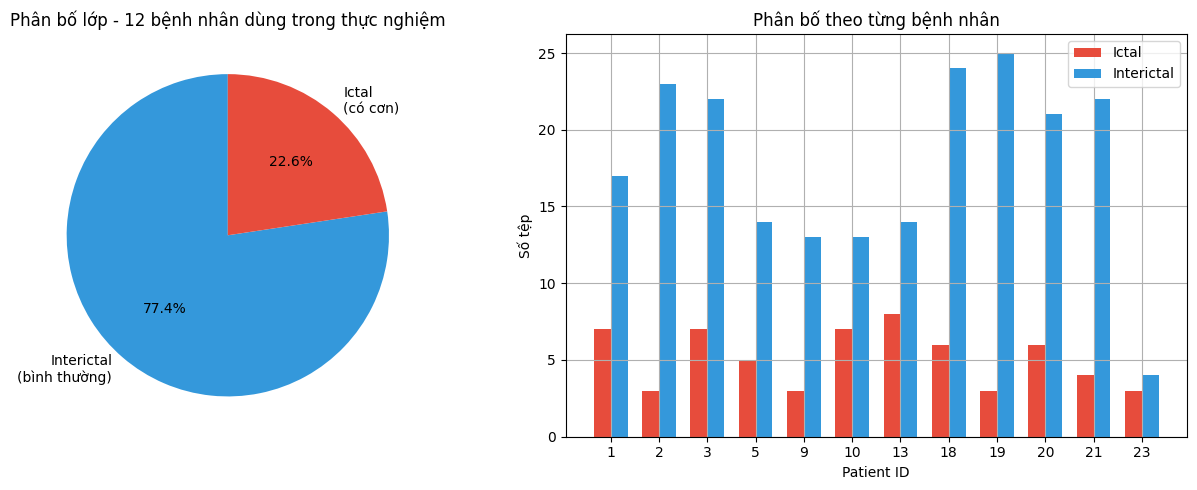

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].pie(
    [n_interictal, n_ictal],
    labels=['Interictal\n(bình thường)', 'Ictal\n(có cơn)'],
    autopct='%1.1f%%',
    colors=['#3498db', '#e74c3c'],
    startangle=90,
)
axes[0].set_title(f'Phân bố lớp - {len(PATIENT_LIST)} bệnh nhân dùng trong thực nghiệm')

ictal_per_patient = pd.Series([get_patient(f) for f in ictal_files]).value_counts()
interictal_per_patient = segment_df[
    (segment_df[1] == 0) & (segment_df['patient'].isin(PATIENT_LIST))
]['patient'].value_counts()

patients_sorted = sorted(PATIENT_LIST, key=int)
x = np.arange(len(patients_sorted))
width = 0.35
axes[1].bar(x - width/2, [ictal_per_patient.get(p, 0) for p in patients_sorted],
            width, label='Ictal', color='#e74c3c')
axes[1].bar(x + width/2, [interictal_per_patient.get(p, 0) for p in patients_sorted],
            width, label='Interictal', color='#3498db')
axes[1].set_xticks(x)
axes[1].set_xticklabels(patients_sorted)
axes[1].set_xlabel('Patient ID')
axes[1].set_ylabel('Số tệp')
axes[1].set_title('Phân bố theo từng bệnh nhân')
axes[1].legend()

plt.tight_layout()
plt.show()

### 2b. Số chiều / feature sau tiền xử lý STFT

Mỗi tệp EEG sau STFT trở thành tensor 4 chiều `(kênh giả, số kênh EEG, số khung thời gian, số
dải tần số)`. Số kênh EEG **không đồng nhất giữa các bệnh nhân** — mã nguồn
(`utils/load_signals_teacher.py`) chọn danh sách kênh khác nhau tuỳ bệnh nhân. Trích xuất trực
tiếp từ source thay vì hardcode, để số liệu luôn khớp mã nguồn hiện tại.

In [11]:
import re

LOAD_SIGNALS_PATH = "../build/CHBMIT/utils/load_signals_teacher.py"

with open(LOAD_SIGNALS_PATH, encoding="utf-8") as f:
    _src = f.read()

# Trích 3 khối "chs = [...]" tương ứng 3 nhánh target in [...]/elif/else trong source thật
_chs_blocks = re.findall(r"chs\s*=\s*\[(.*?)\]", _src, flags=re.S)
_channel_counts = [len(re.findall(r'"[^"]+"', block)) for block in _chs_blocks]
print(f"Số khối 'chs = [...]' tìm thấy trong source: {len(_chs_blocks)}")
print(f"Số kênh mỗi khối (theo đúng thứ tự if/elif/else trong code): {_channel_counts}")

# Khớp đúng thứ tự nhánh trong load_signals_teacher.py: [13,16] -> [4] -> else
n_1316, n_4, n_else = _channel_counts[0], _channel_counts[1], _channel_counts[2]

def n_channels_for(patient):
    if patient in ("13", "16"):
        n = n_1316
    elif patient == "4":
        n = n_4
    else:
        n = n_else
    if patient == "13":
        n -= 1  # drop_channels("T8-P8") riêng cho bệnh nhân 13, xem dòng drop_channels trong source
    return n

PATIENT_LIST = ["1", "3", "5", "9", "13", "23"]
TIME_FRAMES, FREQ_BINS = 59, 114  # đo trực tiếp trên cache thật (xem cell bên dưới)

print("\nSố kênh EEG & shape mỗi mẫu theo bệnh nhân (thực nghiệm này):")
for p in PATIENT_LIST:
    c = n_channels_for(p)
    print(f"  Patient {p:<3s}: {c:2d} kênh  ->  shape (1, {c}, {TIME_FRAMES}, {FREQ_BINS})  "
          f"=  {c*TIME_FRAMES*FREQ_BINS:,} đặc trưng/mẫu")


Số khối 'chs = [...]' tìm thấy trong source: 3
Số kênh mỗi khối (theo đúng thứ tự if/elif/else trong code): [17, 20, 22]

Số kênh EEG & shape mỗi mẫu theo bệnh nhân (thực nghiệm này):
  Patient 1  : 22 kênh  ->  shape (1, 22, 59, 114)  =  147,972 đặc trưng/mẫu
  Patient 3  : 22 kênh  ->  shape (1, 22, 59, 114)  =  147,972 đặc trưng/mẫu
  Patient 5  : 22 kênh  ->  shape (1, 22, 59, 114)  =  147,972 đặc trưng/mẫu
  Patient 9  : 22 kênh  ->  shape (1, 22, 59, 114)  =  147,972 đặc trưng/mẫu
  Patient 13 : 16 kênh  ->  shape (1, 16, 59, 114)  =  107,616 đặc trưng/mẫu
  Patient 23 : 22 kênh  ->  shape (1, 22, 59, 114)  =  147,972 đặc trưng/mẫu


### 2c. Shape thực tế & số lượng cửa sổ (nếu có cache cục bộ)

Phần này đọc trực tiếp cache STFT đã lưu (`cachedir-teacher/ictal_1.hickle`,
`interictal_1.hickle`) nếu tồn tại trên máy — xác nhận shape và đếm số cửa sổ thật, không suy
diễn. Cache này khá nặng (có thể vài GB/bệnh nhân) nên thường không có sẵn trên máy khác hay
trên Kaggle; cell tự bỏ qua nếu thiếu, không báo lỗi.

In [12]:
CACHE_DIR = "../build/CHBMIT/cachedir-teacher"
ictal_path = os.path.join(CACHE_DIR, "ictal_1.hickle")
interictal_path = os.path.join(CACHE_DIR, "interictal_1.hickle")

if os.path.exists(ictal_path) and os.path.exists(interictal_path):
    try:
        import hickle
        X_ictal, y_ictal = hickle.load(ictal_path)
        X_interictal, y_interictal = hickle.load(interictal_path)

        sample_shape = X_ictal[0].shape[1:]  # bỏ chiều "số cửa sổ trong 1 đoạn"
        n_features = int(np.prod(sample_shape))
        sample_bytes = X_ictal[0][0].nbytes

        print(f"Shape mỗi mẫu (đo thật, bệnh nhân 1): {sample_shape}")
        print(f"Số đặc trưng/mẫu: {n_features:,}  (dtype={X_ictal[0].dtype}, "
              f"~{sample_bytes/1024:.1f} KB/mẫu)")

        y_ictal_all = np.concatenate(y_ictal)
        n_segments = len(X_ictal)
        n_windows_ictal = int(sum(x.shape[0] for x in X_ictal))
        n_nonoverlap = int((y_ictal_all == 1).sum())
        n_overlap = int((y_ictal_all == 2).sum())
        n_windows_interictal = int(sum(x.shape[0] for x in X_interictal))

        print(f"\nBệnh nhân 1 — {n_segments} đoạn cơn động kinh:")
        print(f"  Cửa sổ ictal:      {n_windows_ictal} "
              f"({n_nonoverlap} không chồng lấp [test] + {n_overlap} chồng lấp [oversample])")
        print(f"  Cửa sổ interictal: {n_windows_interictal}")
        print(f"  Tỉ lệ mẫu huấn luyện thực tế ictal:interictal ~ "
              f"1:{n_windows_interictal/n_windows_ictal:.1f}")
    except ImportError:
        print("Thiếu thư viện 'hickle' — cài `pip install hickle` để đọc cache thật.")
else:
    print("Không tìm thấy cache cục bộ tại", CACHE_DIR)
    print("Tham khảo số liệu đã đo trước đó (báo cáo chuong2.tex, bệnh nhân 1):")
    print("  Shape mỗi mẫu: (22, 59, 114) -> 147.972 đặc trưng/mẫu (~1,13 MB, float64)")
    print("  946 cửa sổ ictal (12 không chồng lấp + 934 oversample) / 2.040 cửa sổ interictal")


Shape mỗi mẫu (đo thật, bệnh nhân 1): (1, 22, 59, 114)
Số đặc trưng/mẫu: 147,972  (dtype=float64, ~1156.0 KB/mẫu)

Bệnh nhân 1 — 6 đoạn cơn động kinh:
  Cửa sổ ictal:      946 (12 không chồng lấp [test] + 934 chồng lấp [oversample])
  Cửa sổ interictal: 2040
  Tỉ lệ mẫu huấn luyện thực tế ictal:interictal ~ 1:2.2


---
## 3. Tóm tắt

**Mackey-Glass**
- Chuỗi tổng hợp, 10.000 điểm (6000/2000/2000 train/val/test theo bài báo gốc)
- Tự tương quan rất cao ở lag nhỏ (~0.99 tại lag 1), dao động không đơn điệu ở lag lớn -> hệ hỗn loạn có cấu trúc chu kỳ-giả
- Thách thức: độ khó dự báo tăng theo tầm xa (forecasting horizon)
- Số chiều đầu vào: vector 8 chiều (`lookback_window=8`), N~9.988-9.992 mẫu tuỳ horizon

**CHB-MIT**
- Bài báo gốc dùng 12/23 bệnh nhân của cơ sở dữ liệu CHB-MIT
- Mất cân bằng lớp rõ rệt (ictal << interictal) -> lý do dùng AUC-ROC thay vì accuracy
- Tiền xử lý: STFT cửa sổ 30s trên tín hiệu EEG đa kênh (chuẩn 10-20)
- Tensor 4 chiều (kênh giả, số kênh EEG, khung thời gian, dải tần số) -> `(1, 22, 59, 114)`
  cho hầu hết bệnh nhân, nhưng **không đồng nhất**: bệnh nhân 13 chỉ có 16 kênh (107.616 đặc
  trưng/mẫu, ít hơn ~27%) do mã nguồn tự loại kênh trùng `T8-P8`
- Mất cân bằng lớp ở mức mẫu huấn luyện (sau oversampling) nhẹ hơn nhiều so với mức mẫu thô:
  ictal:interictal ~ 1:2,2 (bệnh nhân 1), so với ~1:3,4 nếu đếm theo số tệp